# Поиск автомобиля на фото

## 1. Загрузка модели

In [21]:
from math import ceil, floor
from pathlib import Path

import cv2
import numpy as np
from IPython.display import display
from PIL import Image, ImageDraw, ImageOps
from ultralytics import YOLO

model = YOLO("../models/yolo11n.pt")
car_class_id = next(class_id for class_id, name in model.names.items() if name == "car")

## 2. Входное изображение

In [22]:
image_path = Path("../dataset/1.jpg")

with Image.open(image_path) as source_image:
    image = ImageOps.exif_transpose(source_image).convert("RGB")

## 3. Детекция автомобилей

In [23]:
decision_threshold = 0.25
candidate_threshold = 0.01

result = model.predict(
    image,
    classes=[car_class_id],
    conf=candidate_threshold,
    verbose=False,
)[0]

car_boxes = result.boxes
accepted = car_boxes.conf >= decision_threshold
cars = result[accepted]

if len(cars.boxes):
    areas = cars.boxes.xywh[:, 2:].prod(dim=1)
    largest_index = areas.argmax().item()
    coords = cars.boxes.xyxy[largest_index].tolist()
    confidence = cars.boxes.conf[largest_index].item()

## 4. Вывод результата

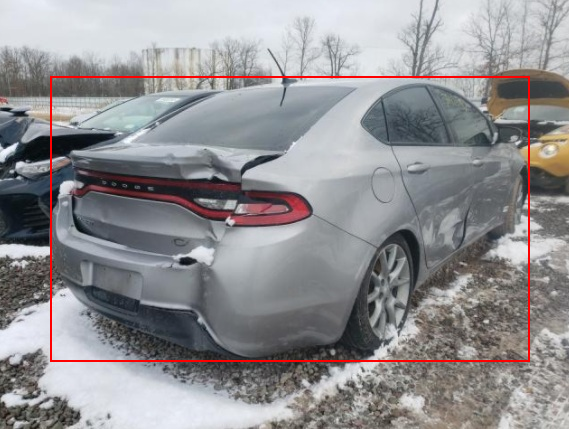

Уверенность: 83.0%


In [24]:
if len(cars.boxes):
    annotated_image = image.copy()
    draw = ImageDraw.Draw(annotated_image)
    line_width = max(2, round(max(image.size) / 300))
    draw.rectangle(coords, outline="red", width=line_width)
    display(annotated_image)
    print(f"Уверенность: {confidence:.1%}")
else:
    print("на фото нет автомобиля")
    if len(car_boxes):
        best_score = car_boxes.conf.max().item()
        print(f"Уверенность в наличии автомобиля: {best_score:.1%} (порог: {decision_threshold:.0%})")
    else:
        print(f"Уверенность в наличии автомобиля: ниже {candidate_threshold:.0%}")

## 5. Сохранение области автомобиля в PNG

In [25]:
if len(cars.boxes):
    x1, y1, x2, y2 = coords
    left, top = max(0, floor(x1)), max(0, floor(y1))
    right, bottom = min(image.width, ceil(x2)), min(image.height, ceil(y2))
    crop_rgb = np.asarray(image)[top:bottom, left:right]
    crop_bgr = cv2.cvtColor(crop_rgb, cv2.COLOR_RGB2BGR)

    output_path = Path("../outputs") / f"{image_path.stem}.png"
    success, png = cv2.imencode(".png", crop_bgr)
    if not success:
        raise OSError(f"Не удалось закодировать PNG: {output_path}")
    output_path.parent.mkdir(parents=True, exist_ok=True)
    output_path.write_bytes(png.tobytes())
    print(f"Сохранено: {output_path}")

Сохранено: ..\outputs\1.png
